# 22. Fourier Analysis on Manifolds

This notebook follows “Fourier analysis on Manifolds” in Section 4.4 of Bronstein, Bruna, Cohen, and Veličković, *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges*, printed pages 52–56. M. A. Toth’s spectral-geometry notes provide complementary context.

The key idea is to replace Euclidean Fourier modes with eigenfunctions of the **Laplace–Beltrami operator**. These modes encode intrinsic geometry and provide a basis for analysing and filtering scalar signals on a manifold.

**Learning goals**
- Connect gradient, divergence, Laplacian, and Dirichlet energy.
- Interpret Laplacian eigenfunctions as manifold Fourier modes.
- Define spectral convolution and understand its instability.
- Derive polynomial filters without eigendecomposition.
- Explain spatial convolution, local frames (gauges), and the Poincaré–Hopf obstruction.

## 1. From Euclidean Fourier analysis to manifolds

On a periodic Euclidean domain, Fourier modes are eigenfunctions of translation-invariant differential operators. For example,

$$-\frac{d^2}{dx^2}e^{i\xi x}=\xi^2e^{i\xi x}.$$

This suggests using eigenfunctions of an intrinsic differential operator as the frequency modes of a general geometric domain. A Riemannian metric $g$ determines lengths, angles, volume, and differential operators, so the Laplace–Beltrami operator provides a geometric notion of frequency without requiring global translations or an ambient coordinate system.

## 2. Gradient, divergence, and Laplace–Beltrami operator

For a smooth scalar field $x$ on a Riemannian manifold $(\mathcal M,g)$, its gradient $\nabla x$ is the tangent vector field pointing in the direction of steepest increase. The metric identifies the differential $dx_p$ with a tangent vector:

$$dx_p(X)=g_p(\nabla x(p),X),\qquad X\in T_p\mathcal M.$$

A vector field can be viewed as a flow. Its divergence measures local net outflow: positive values indicate source-like behaviour and negative values sink-like behaviour. We use the proto-book’s adjoint notation $\nabla^*$ (divergence operator):

$$\langle X,\nabla x\rangle=\langle\nabla^*X,x\rangle.$$

The Laplace–Beltrami operator is

$$\boxed{\Delta=\nabla^*\nabla.}$$

With this convention, $\Delta$ is nonnegative on a compact manifold without boundary. (Other texts sometimes define the Laplacian with the opposite sign.)

**Properties:** it is intrinsic to the Riemannian geometry, invariant under isometries (under the natural pullback of functions), and self-adjoint under suitable boundary assumptions:

$$\langle x,\Delta y\rangle=\langle\Delta x,y\rangle.$$

The standard Laplacian is isotropic: it does not privilege a tangent direction. Anisotropic variants can be formed by inserting a position-dependent tensor between gradient and divergence.

## 3. Dirichlet energy and smoothness

The quadratic form of the gradient is the **Dirichlet energy**:

$$\mathcal E(x)=\|\nabla x\|_{L^2}^2=\int_{\mathcal M}g(\nabla x,\nabla x)\,dV.$$

For a compact manifold without boundary (or suitable boundary conditions), integration by parts gives

$$\mathcal E(x)=\langle x,\Delta x\rangle.$$

The energy penalizes rapid variation: a signal that changes sharply across nearby points generally has higher energy than a slowly varying signal. In geometric learning, this gives a natural smoothness regularizer for signals or features on a mesh or manifold.

## 4. Laplacian eigenfunctions as Fourier modes

On a compact Riemannian manifold, the Laplace–Beltrami operator has a discrete spectrum and an orthonormal eigenbasis (counting multiplicity):

$$\boxed{\Delta\phi_k=\lambda_k\phi_k,\qquad 0=\lambda_0\leq\lambda_1\leq\cdots.}$$

For a connected manifold, the zero eigenspace consists of constant functions. The eigenvalues play the role of squared frequencies: low eigenvalues correspond to smoother modes, while higher eigenvalues correspond to more rapid variation.

### Variational interpretation

The eigenfunctions can be viewed as successive minimizers of Dirichlet energy under unit-norm and orthogonality constraints:

$$\phi_{k+1}=\operatorname*{arg\,min}_{\phi}\mathcal E(\phi)
\quad\text{s.t.}\quad \|\phi\|_{L^2}=1,\quad
\langle\phi,\phi_j\rangle=0\;\;(j=0,\ldots,k).$$

### Fourier coefficients and reconstruction

For $x\in L^2(\mathcal M)$,

$$\widehat{x}_k=\langle x,\phi_k\rangle,\qquad
x(u)=\sum_{k=0}^{\infty}\widehat{x}_k\phi_k(u),$$

where reconstruction is understood in the $L^2$ sense. Truncating to $K$ modes gives $x_K(u)=\sum_{k=0}^{K}\widehat{x}_k\phi_k(u)$, a natural low-frequency approximation.

## 5. Computational illustration: Fourier modes on the circle

**What the code demonstrates:** the circle is a simple manifold whose Laplacian eigenfunctions are trigonometric modes. We build a signal with both low- and high-frequency components and reconstruct it after removing high frequencies.

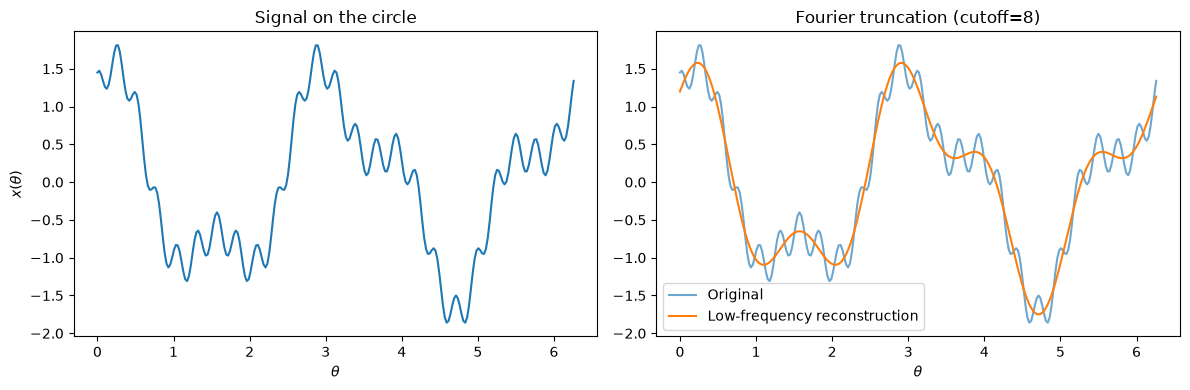

In [1]:
import numpy as np
import matplotlib.pyplot as plt

n = 256
theta = 2 * np.pi * np.arange(n) / n
signal = 1.2*np.cos(2*theta) + 0.55*np.sin(5*theta) + 0.25*np.cos(24*theta)

coefficients = np.fft.fft(signal)
frequencies = np.fft.fftfreq(n, d=1/n)
cutoff = 8
filtered_coefficients = coefficients.copy()
filtered_coefficients[np.abs(frequencies) > cutoff] = 0
reconstruction = np.fft.ifft(filtered_coefficients).real

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(theta, signal)
axes[0].set(title="Signal on the circle", xlabel=r"$\theta$", ylabel=r"$x(\theta)$")
axes[1].plot(theta, signal, label="Original", alpha=0.65)
axes[1].plot(theta, reconstruction, label="Low-frequency reconstruction")
axes[1].set(title=f"Fourier truncation (cutoff={cutoff})", xlabel=r"$\theta$")
axes[1].legend()
plt.tight_layout()
plt.show()

The circle is a special case: its eigenmodes are known analytically. On a general manifold, one typically approximates a Laplace–Beltrami operator numerically and computes its eigenvectors. On a triangle mesh, these eigenvectors serve as discrete spectral modes.

## 6. Spectral convolution on manifolds

Inspired by the Euclidean convolution theorem, define manifold spectral convolution by multiplying the Fourier coefficients of signal $x$ and filter $\theta$:

$$\boxed{(x\star\theta)(u)=\sum_{k\geq0}
(\widehat{x}_k\,\widehat{\theta}_k)\phi_k(u).}$$

Because the Laplacian is intrinsic, this construction is isometry-invariant when the signal and filter are transported consistently. But invariance does not imply stability under small geometric perturbations.

## 7. Why raw spectral filters can be unstable

A direct spectral filter learns a separate coefficient for each eigenmode. Eigenfunctions—especially those belonging to repeated or close eigenvalues—can change substantially under small perturbations. An eigenfunction can flip sign, and a basis of a repeated-eigenvalue eigenspace can rotate while the eigenspace itself remains essentially unchanged.

Thus applying the same mode-wise coefficients to nearly isometric domains can yield different outputs. The problem is not that the Laplacian is non-intrinsic; rather, the filter may depend too directly on a particular choice of eigenvectors.

## 8. Stable spectral transfer functions

Instead of assigning unrelated parameters to individual eigenvectors, apply a scalar function to the eigenvalues:

$$\widehat p(\Delta)x=\sum_{k\geq0}\widehat p(\lambda_k)
\langle x,\phi_k\rangle\phi_k.$$

Equivalently,

$$(\widehat p(\Delta)x)(u)=\int_{\mathcal M}x(v)
\left(\sum_{k\geq0}\widehat p(\lambda_k)\phi_k(v)\phi_k(u)\right)dV(v).$$

This is both a spectral filter and a spatially varying kernel. If $\widehat p$ is a polynomial,

$$\widehat p(\lambda)=\sum_{\ell=0}^{r}\alpha_\ell\lambda^\ell,$$

then

$$\boxed{\widehat p(\Delta)x=\sum_{\ell=0}^{r}\alpha_\ell\Delta^\ell x.}$$

This can be computed using repeated Laplacian applications, avoiding explicit eigendecomposition. Low-degree polynomial filters are also local for sparse discrete Laplacians. Hence the “spectral” and “spatial” categories are not entirely separate.

## 9. Computational illustration: polynomial in a discrete Laplacian

**What the code demonstrates:** apply a polynomial in the cycle-graph Laplacian directly to a localized signal, without computing any eigenvectors. This is a discrete analogue of polynomial spectral filtering, not a full discretization of the smooth Laplace–Beltrami operator.

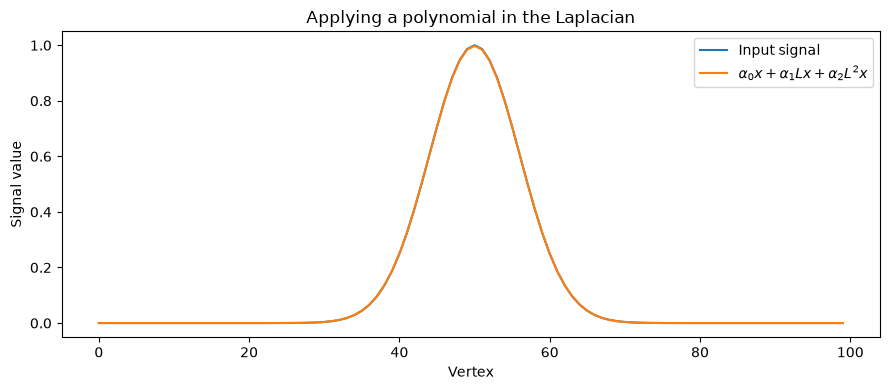

In [2]:
import numpy as np
import matplotlib.pyplot as plt

n = 100
A = np.zeros((n, n))
for i in range(n):
    A[i, (i-1) % n] = 1
    A[i, (i+1) % n] = 1
L = np.diag(A.sum(axis=1)) - A

positions = np.arange(n)
x = np.exp(-0.5 * ((positions - n/2) / 6)**2)
alpha0, alpha1, alpha2 = 1.0, -0.08, 0.002
filtered = alpha0*x + alpha1*(L @ x) + alpha2*(L @ (L @ x))

plt.figure(figsize=(9, 4))
plt.plot(positions, x, label="Input signal")
plt.plot(positions, filtered, label=r"$\alpha_0x+\alpha_1Lx+\alpha_2L^2x$")
plt.xlabel("Vertex")
plt.ylabel("Signal value")
plt.title("Applying a polynomial in the Laplacian")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Spatial convolution on manifolds

A local alternative uses the exponential map to sample the signal from a tangent space:

$$(x\star\theta)(u)=\int_{T_u\mathcal M}
x(\exp_u Y)\,\theta_u(Y)\,dY.$$

Here $\exp_u(Y)$ follows the geodesic starting at $u$ with initial velocity $Y$ for unit time. The filter $\theta_u$ lives in the tangent space at $u$ and should have local support, typically within a region controlled by the injectivity radius.

This resembles ordinary convolution, but each point has a different tangent space. To compute with a tangent vector, we must represent it in a local basis.

## 11. Local frames and the gauge problem

A local frame is a linear isomorphism

$$\omega_u:\mathbb R^d\longrightarrow T_u\mathcal M,$$

which identifies tangent vectors with coordinate vectors. In such coordinates, a local filter can be written schematically as

$$(x\star\theta)(u)=\int_{[0,1]^d}
x\big(\exp_u(\omega_u y)\big)\theta(y)\,dy.$$

This introduces a **gauge choice**: a basis choice in every tangent space.

Two obstacles arise:

1. A smooth global frame may not exist. Some manifolds are not parallelizable.
2. There is generally no canonical frame. Different choices rotate the filter coordinates and can change the output.

Parallel transport moves frames between points, but on curved manifolds it can depend on the path. Thus a filter cannot always be moved around a manifold as simply as it is translated on a grid.

## 12. The hairy-ball theorem and Poincaré–Hopf

The sphere $S^2$ admits no continuous, everywhere nonzero tangent vector field—the informal “hairy-ball theorem.”

The broader **Poincaré–Hopf theorem** states that for a compact differentiable manifold $M$ without boundary and a vector field $V$ with isolated zeros,

$$\boxed{\sum_{p:V(p)=0}\operatorname{ind}_p(V)=\chi(M),}$$

where $\operatorname{ind}_p(V)$ is the index of a zero and $\chi(M)$ is the Euler characteristic. Since $\chi(S^2)=2$, a tangent vector field on $S^2$ cannot have no zeros: otherwise the sum would be $0$, a contradiction.

This topological obstruction explains why a globally smooth, nonsingular gauge cannot be chosen on the sphere. Practical methods may build frames that are smooth except at a limited number of singularities, for example from gradients of intrinsic scalar fields. Near singularities, however, frame orientation can change rapidly.

**Connection to geometric deep learning:** gauge-aware and gauge-equivariant methods explicitly account for changes of local frame rather than assuming a canonical tangent basis exists.

## 13. Summary

| Construction | Main idea | Main caveat |
|---|---|---|
| Manifold Fourier basis | Eigenfunctions of $\Delta$ | Eigenvectors may be unstable under perturbations |
| Spectral convolution | Multiply Fourier coefficients | Mode-wise parameters can depend on eigenbasis choices |
| Spectral transfer function | Apply $\widehat p(\Delta)$ | Direct eigendecomposition may be expensive |
| Polynomial filter | $\sum_{\ell=0}^r\alpha_\ell\Delta^\ell$ | Higher degree increases computation and receptive field |
| Spatial convolution | Filter in $T_u\mathcal M$ via $\exp_u$ | Requires local frames and careful transport |
| Gauge-aware learning | Track changes of local frame | Requires bundle-aware representations |

The Laplacian connects Riemannian geometry, Fourier analysis, and geometric learning. Its eigenfunctions define intrinsic frequencies; polynomial functions of the Laplacian can improve efficiency and stability; spatial constructions reveal the gauge problem that motivates gauge-equivariant methods.

## Exercises

1. Verify that $\cos(k\theta)$ and $\sin(k\theta)$ are eigenfunctions of the circle Laplacian, and identify their eigenvalues under the nonnegative convention.
2. Why does a constant function have zero Dirichlet energy? What does this imply about the zero eigenvalue on a connected compact manifold?
3. Modify the circle example to compare several Fourier cutoffs. How does the reconstruction change?
4. Expand $(I-\tau L)^2x$ as a polynomial in $L$. Which operator applications are needed?
5. Why can an eigenbasis change when eigenvalues are repeated or nearly repeated, even if the corresponding eigenspace changes little?
6. Explain why a filter that treats the first frame coordinate as a preferred direction can depend on the choice of local frame.
7. Use $\chi(S^2)=2$ and Poincaré–Hopf to explain why no global smooth nonsingular tangent frame exists on $S^2$.
8. Compare polynomial Laplacian filters with local-frame spatial filters: what geometry does each use, and what are their main limitations?

## References

- M. Bronstein, J. Bruna, T. Cohen, and P. Veličković, *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges*, Section 4.4, “Fourier analysis on Manifolds,” printed pp. 52–56.
- M. A. Toth, *Spectral Geometry* lecture notes: [PDF](https://www.math.mcgill.ca/toth/spectral%20geometry.pdf).
- Standard differential topology texts for the Poincaré–Hopf and hairy-ball theorems.

This notebook is an explanatory study guide, not a verbatim reproduction of the references.